---
Détection d'Anomalies
---
## Objectif
L’objectif de ce travail est de détecter automatiquement les anomalies
à partir de données techniques en comparant plusieurs algorithmes
de classification supervisée.

---
Imports
---

In [1]:
# Données
import numpy  as np
import pandas as pd

# Visualisation 
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style='whitegrid')
%matplotlib inline

# Prétraitement 
from sklearn.preprocessing   import StandardScaler
from sklearn.model_selection import (
    train_test_split, cross_val_score, StratifiedKFold
)
from sklearn.pipeline import Pipeline

# Algorithmes 
from sklearn.tree          import DecisionTreeClassifier
from sklearn.svm           import SVC
from sklearn.neighbors     import KNeighborsClassifier

# Évaluation
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report,
    confusion_matrix, roc_curve, roc_auc_score
)

# SMOTE (rééquilibrage classes)
from imblearn.over_sampling import SMOTE
from imblearn.pipeline      import Pipeline as ImbPipeline



# Palette globale
CN          = '#2196F3'   # bleu  = Normal
CA          = '#F44336'   # rouge = Anomalie
ALGO_COLORS = ['#3F51B5','#9C27B0','#FF9800','#E53935','#43A047']



---
Chargement & suppression du Data Leakage
---



In [2]:

df = pd.read_excel('dataset_ml.xlsx')

COLS_EXCLUES = [
    'ID_LIGNE', 'ID_CARTE_OLT', 'NO_PORT', 'ONU_ID',
    'DESGOUV',
    'Anomalie_technique', 'Anomalie_admin',
    'Etat_OLT_TX', 'Etat_OLT_RX',
    'Etat_ONU_TX', 'Etat_ONU_RX'
]

X = df.drop(columns=COLS_EXCLUES + ['Anomalie'])
y = df['Anomalie']
FEATURES = list(X.columns)

print(f'Dataset chargé : {df.shape[0]} lignes')
print(f'Features ({len(FEATURES)}) : {FEATURES}')
print(f'Normaux   : {(y==0).sum()}  ({(y==0).mean()*100:.1f}%)')
print(f'Anomalies : {(y==1).sum()}  ({(y==1).mean()*100:.1f}%)')
X.head()

Dataset chargé : 6692 lignes
Features (7) : ['F_SUSP', 'ADMIN_STATUS', 'OPER_STATUS', 'OLT_POWER_TX', 'OLT_RX_ONT_POWER', 'ONU_POWER_TX', 'ONU_POWER_RX']
Normaux   : 6046  (90.3%)
Anomalies : 646  (9.7%)


,F_SUSP,ADMIN_STATUS,OPER_STATUS,OLT_POWER_TX,OLT_RX_ONT_POWER,ONU_POWER_TX,ONU_POWER_RX
0,0,1,1,3.4,-20.3,2.364,-19.43
1,0,1,1,3.4,-20.3,2.364,-19.43
2,0,1,1,3.4,-20.3,2.364,-19.43
3,0,1,1,3.4,-20.3,2.364,-19.43
4,0,1,1,3.4,-20.3,2.364,-19.43


---
 EDA : Distribution de la cible
 ---

In [3]:
df['Anomalie'] = df['Anomalie'].astype(int)

C:\Users\mahmo\AppData\Local\Temp\ipykernel_16160\472250106.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Anomalie', palette={'0': CN, '1': CA}, ax=ax)
C:\Users\mahmo\AppData\Local\Temp\ipykernel_16160\472250106.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Normal (0)', 'Anomalie (1)'])


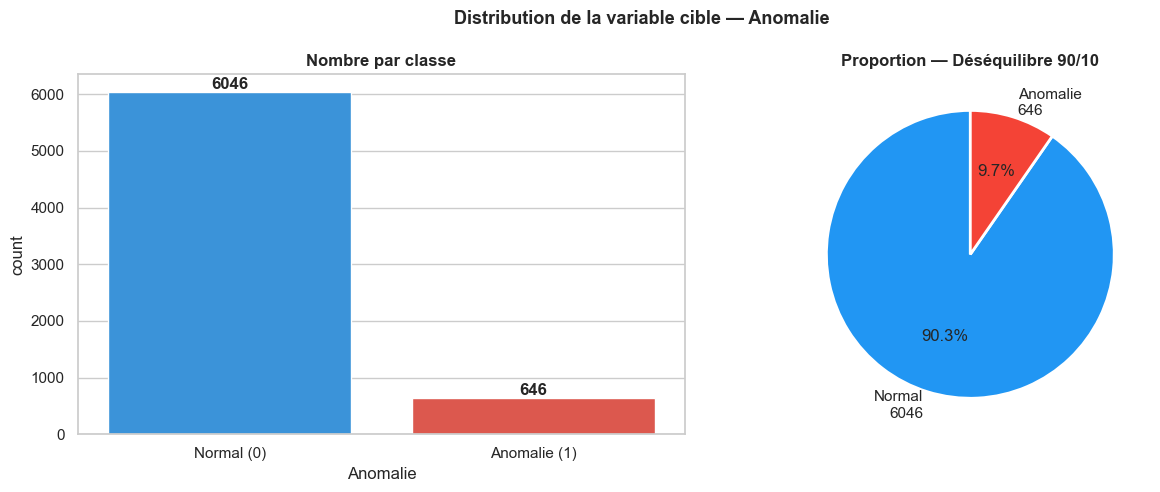

→ Déséquilibre important : SMOTE sera appliqué sur le train uniquement


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle('Distribution de la variable cible — Anomalie',
             fontsize=13, fontweight='bold')

ax = axes[0]
sns.countplot(data=df, x='Anomalie', palette={'0': CN, '1': CA}, ax=ax)
ax.set_title('Nombre par classe', fontweight='bold')
ax.set_xticklabels(['Normal (0)', 'Anomalie (1)'])
for p in ax.patches:
    ax.text(p.get_x()+p.get_width()/2, p.get_height()+40,
            str(int(p.get_height())), ha='center', fontsize=12, fontweight='bold')

n0, n1 = (y==0).sum(), (y==1).sum()
axes[1].pie([n0, n1],
            labels=[f'Normal\n{n0}', f'Anomalie\n{n1}'],
            colors=[CN, CA], autopct='%1.1f%%', startangle=90,
            wedgeprops={'edgecolor': 'white', 'linewidth': 2})
axes[1].set_title('Proportion — Déséquilibre 90/10', fontweight='bold')

plt.tight_layout()
plt.show()
print('→ Déséquilibre important : SMOTE sera appliqué sur le train uniquement')

---
Heatmap de corrélation
---

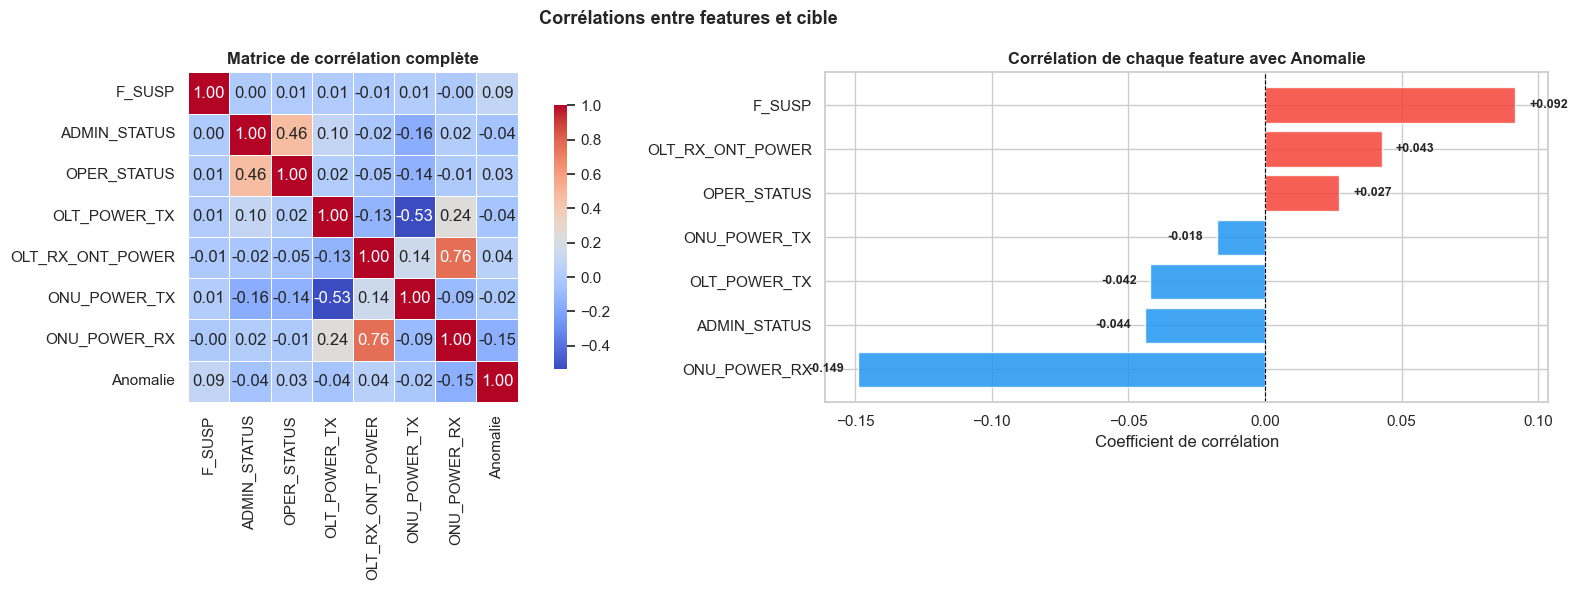

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
fig.suptitle('Corrélations entre features et cible', fontsize=13, fontweight='bold')

corr = df[FEATURES + ['Anomalie']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, square=True,
            cbar_kws={'shrink': 0.8}, ax=axes[0])
axes[0].set_title('Matrice de corrélation complète', fontweight='bold')

corr_target = corr['Anomalie'].drop('Anomalie').sort_values()
colors_bar  = [CA if v > 0 else CN for v in corr_target.values]
axes[1].barh(corr_target.index, corr_target.values,
             color=colors_bar, alpha=0.85, edgecolor='white')
axes[1].axvline(0, color='black', lw=0.8, ls='--')
axes[1].set_title('Corrélation de chaque feature avec Anomalie', fontweight='bold')
axes[1].set_xlabel('Coefficient de corrélation')
for i, v in enumerate(corr_target.values):
    axes[1].text(v + 0.005 if v >= 0 else v - 0.005, i, f'{v:+.3f}',
                 va='center', fontsize=9, fontweight='bold',
                 ha='left' if v >= 0 else 'right')

plt.tight_layout()
plt.show()

---
Histogrammes : Normal vs Anomalie
---

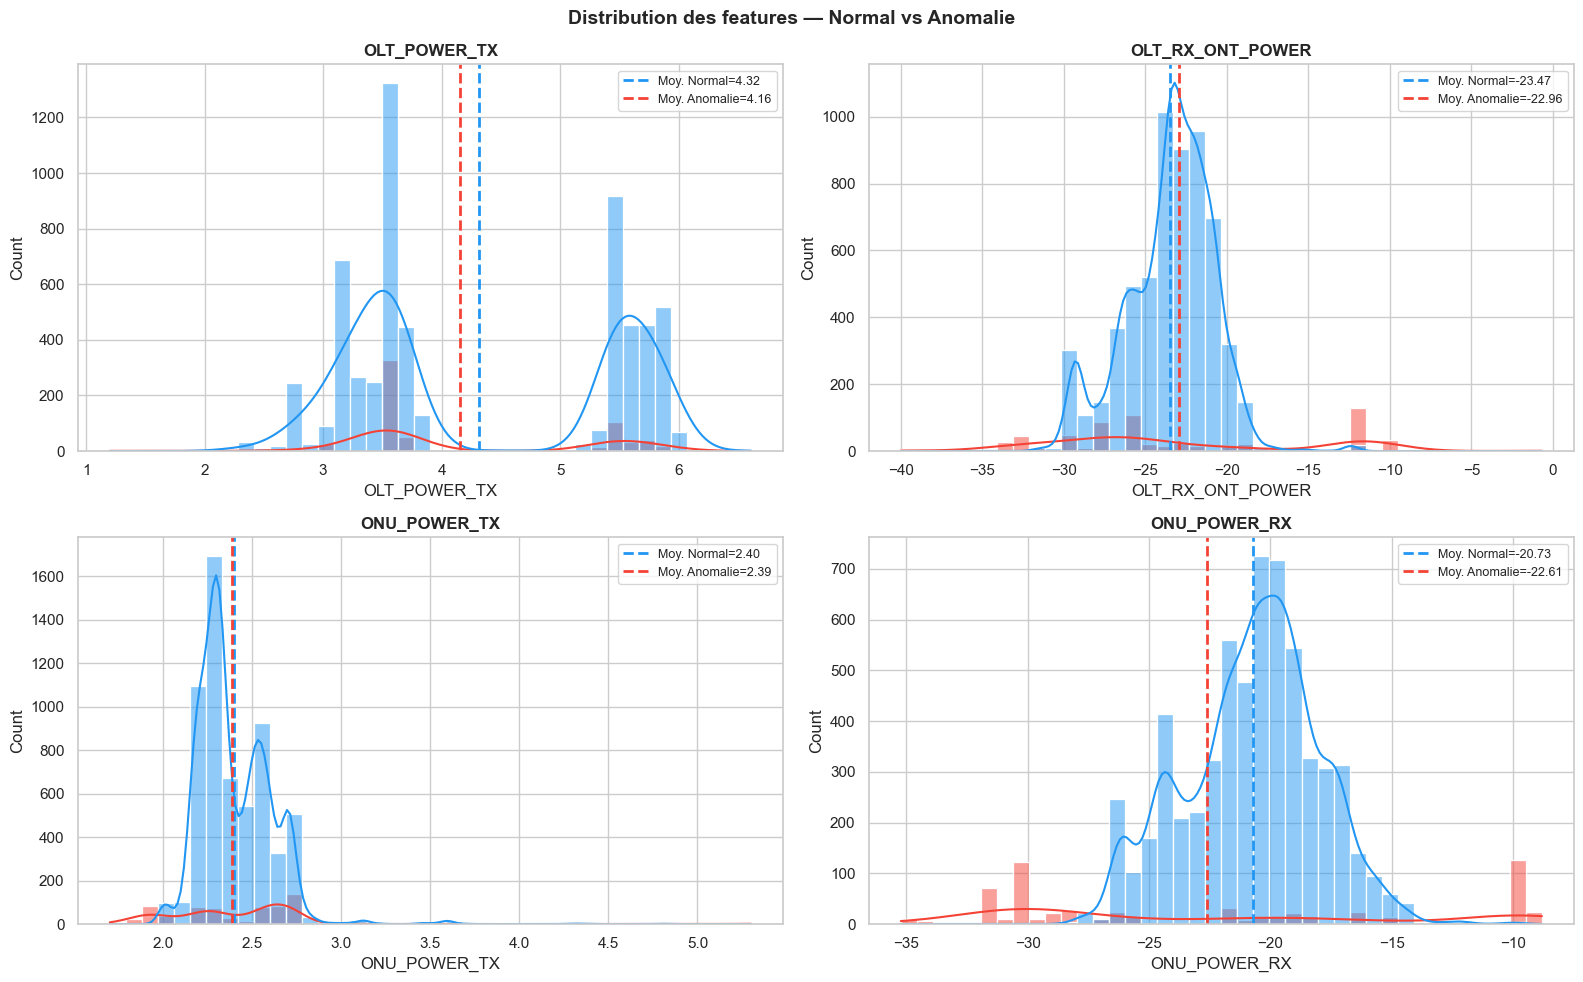

In [6]:
normal   = df[df.Anomalie == 0]
anomalie = df[df.Anomalie == 1]

num_vars = ['OLT_POWER_TX', 'OLT_RX_ONT_POWER', 'ONU_POWER_TX', 'ONU_POWER_RX']

fig, axs = plt.subplots(2, 2, figsize=(16, 10))
axs = axs.flatten()
fig.suptitle('Distribution des features — Normal vs Anomalie',
             fontsize=14, fontweight='bold')

for i, var in enumerate(num_vars):
    sns.histplot(x=var, data=df, hue='Anomalie',
                 ax=axs[i], kde=True, bins=40, alpha=0.5,
                 palette={0: CN, 1: CA})
    moy_n = normal[var].mean()
    moy_a = anomalie[var].mean()
    axs[i].axvline(moy_n, color=CN, ls='--', lw=2, label=f'Moy. Normal={moy_n:.2f}')
    axs[i].axvline(moy_a, color=CA, ls='--', lw=2, label=f'Moy. Anomalie={moy_a:.2f}')
    axs[i].set_title(var, fontsize=12, fontweight='bold')
    axs[i].legend(fontsize=9)

plt.tight_layout()
plt.show()

---
Scatter plot : OLT_POWER_TX vs ONU_POWER_TX
**Rôle :** Visualiser la séparation spatiale entre Normal et Anomalie.
---

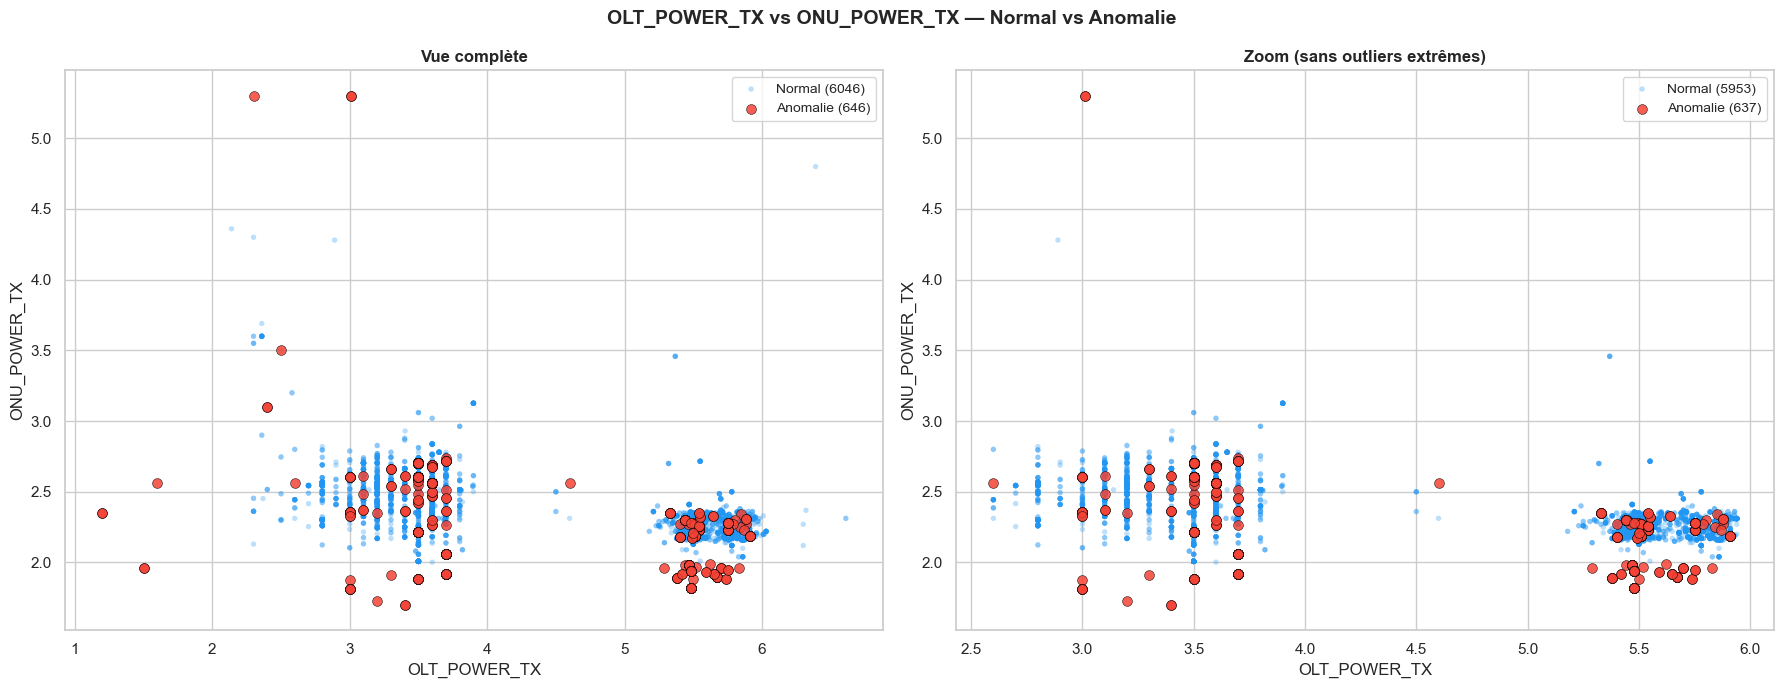

In [7]:
normal   = df[df.Anomalie == 0]
anomalie = df[df.Anomalie == 1]

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('OLT_POWER_TX vs ONU_POWER_TX — Normal vs Anomalie',
             fontsize=14, fontweight='bold')

for ax, (title, df_n, df_a) in zip(axes, [
    ('Vue complète', normal, anomalie),
    ('Zoom (sans outliers extrêmes)',
     normal[normal.OLT_POWER_TX.between(*df.OLT_POWER_TX.quantile([0.01,0.99]))],
     anomalie[anomalie.OLT_POWER_TX.between(*df.OLT_POWER_TX.quantile([0.01,0.99]))])
]):
    ax.scatter(df_n['OLT_POWER_TX'], df_n['ONU_POWER_TX'],
               c='#2196F3', alpha=0.3, s=15, label=f'Normal ({len(df_n)})', edgecolor='none')
    ax.scatter(df_a['OLT_POWER_TX'], df_a['ONU_POWER_TX'],
               c='#F44336', alpha=0.85, s=50, label=f'Anomalie ({len(df_a)})',
               edgecolor='black', linewidth=0.4, zorder=5)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('OLT_POWER_TX')
    ax.set_ylabel('ONU_POWER_TX')
    ax.legend(fontsize=10)

plt.tight_layout()
plt.show()

---
 Prétraitement : Split + SMOTE + Scaling

```
1. Split train/test  (stratify=y → respecte le ratio 90/10)
2. SMOTE sur TRAIN uniquement  (jamais sur le test !)
3. StandardScaler  fit sur train SMOTE, transform sur test seulement
```

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_sm)
X_test_s  = scaler.transform(X_test)

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

print('AVANT SMOTE :')
print(f'  Train : {len(X_train)}  (normaux={(y_train==0).sum()}  anomalies={(y_train==1).sum()})')
print()
print('APRÈS SMOTE (train uniquement) :')
print(f'  Train : {len(X_train_sm)}  (normaux={(y_train_sm==0).sum()}  anomalies={(y_train_sm==1).sum()})')
print()
print('TEST (non touché) :')
print(f'  Test  : {len(X_test)}   (normaux={(y_test==0).sum()}  anomalies={(y_test==1).sum()})')

AVANT SMOTE :
  Train : 4684  (normaux=4232  anomalies=452)

APRÈS SMOTE (train uniquement) :
  Train : 8464  (normaux=4232  anomalies=4232)

TEST (non touché) :
  Test  : 2008   (normaux=1814  anomalies=194)


---
ALGORITHME 1 : Decision Tree

**Principe :** Apprend des règles SI/ALORS en divisant les données récursivement.  
**Avantage :** Très interprétable — on peut lire les règles de décision.  
**Inconvénient :** Sur-apprend facilement si max_depth non limité.

---

In [9]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train_s, y_train_sm)

y_pred_dt  = dt_model.predict(X_test_s)
y_proba_dt = dt_model.predict_proba(X_test_s)[:, 1]
auc_dt     = roc_auc_score(y_test, y_proba_dt)

print('═' * 55)
print('  DECISION TREE')
print('═' * 55)
print(classification_report(y_test, y_pred_dt, target_names=['Normal','Anomalie']))
print(f'AUC-ROC : {auc_dt:.4f}')

pipe_dt = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('sc',    StandardScaler()),
    ('clf',   DecisionTreeClassifier(random_state=42))
])
cv_dt = cross_val_score(pipe_dt, X, y, cv=cv, scoring='f1', n_jobs=-1)
print(f'Cross-val F1 (10-fold) : {cv_dt.mean():.4f} ± {cv_dt.std():.4f}')

═══════════════════════════════════════════════════════
  DECISION TREE
═══════════════════════════════════════════════════════
              precision    recall  f1-score   support

      Normal       1.00      0.99      1.00      1814
    Anomalie       0.95      1.00      0.97       194

    accuracy                           0.99      2008
   macro avg       0.97      1.00      0.98      2008
weighted avg       0.99      0.99      0.99      2008

AUC-ROC : 0.9970
Cross-val F1 (10-fold) : 0.9908 ± 0.0073


---
ALGORITHME 2 : SVM

**Principe :** Cherche la frontière de séparation à marge maximale.  
**Avantage :** Très efficace sur mesures continues (dBm), frontière lisse.  
**Note :** `probability=True` est obligatoire pour `predict_proba` et la courbe ROC.

---

In [10]:
svm_model = SVC(kernel='rbf', probability=True, random_state=42)
svm_model.fit(X_train_s, y_train_sm)

y_pred_svm  = svm_model.predict(X_test_s)
y_proba_svm = svm_model.predict_proba(X_test_s)[:, 1]
auc_svm     = roc_auc_score(y_test, y_proba_svm)

print('═' * 55)
print('  SVM (rbf, probability=True)')
print('═' * 55)
print(classification_report(y_test, y_pred_svm, target_names=['Normal','Anomalie']))
print(f'AUC-ROC : {auc_svm:.4f}')

pipe_svm = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('sc',    StandardScaler()),
    ('clf',   SVC(kernel='rbf', probability=True, random_state=42))
])
cv_svm = cross_val_score(pipe_svm, X, y, cv=cv, scoring='f1', n_jobs=-1)
print(f'Cross-val F1 (10-fold) : {cv_svm.mean():.4f} ± {cv_svm.std():.4f}')

═══════════════════════════════════════════════════════
  SVM (rbf, probability=True)
═══════════════════════════════════════════════════════
              precision    recall  f1-score   support

      Normal       1.00      0.99      0.99      1814
    Anomalie       0.91      0.99      0.95       194

    accuracy                           0.99      2008
   macro avg       0.96      0.99      0.97      2008
weighted avg       0.99      0.99      0.99      2008

AUC-ROC : 0.9995
Cross-val F1 (10-fold) : 0.9584 ± 0.0150


---
ALGORITHME 3 : KNN

**Principe :** Classe selon les k voisins les plus proches (vote majoritaire).  
**Avantage :** Simple, pas de phase d'entraînement complexe.  
**Inconvénient :** Sensible aux outliers, lent à la prédiction sur grands datasets.

---

Tester les KNN et choisir le meilleur k.

In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import f1_score

k_values = [3, 5, 7, 9,11]

best_k  = None
best_f1 = 0

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_s, y_train_sm)  # ← X_train_s et non X_train_sm
    
    preds = knn.predict(X_test_s)
    f1    = f1_score(y_test, preds)
    
    print(f"K={k:2d}  F1={f1:.4f}")
    
    if f1 > best_f1:
        best_f1 = f1
        best_k  = k

print(f"\n✅ Meilleur K : {best_k}  |  Meilleur F1 : {best_f1:.4f}")

K= 3  F1=0.9695
K= 5  F1=0.9698
K= 7  F1=0.9698
K= 9  F1=0.9674
K=11  F1=0.9626

✅ Meilleur K : 5  |  Meilleur F1 : 0.9698


In [12]:
knn_model5 = KNeighborsClassifier(n_neighbors=5)
knn_model5.fit(X_train_s, y_train_sm)

y_pred_knn5  = knn_model5.predict(X_test_s)
y_proba_knn5 = knn_model5.predict_proba(X_test_s)[:, 1]
auc_knn5     = roc_auc_score(y_test, y_proba_knn5)

print(classification_report(y_test, y_pred_knn5, target_names=['Normal','Anomalie']))
print(f'AUC-ROC : {auc_knn5:.4f}')

pipe_knn = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('sc',    StandardScaler()),
    ('clf',   KNeighborsClassifier(n_neighbors=5))
])
cv_knn = cross_val_score(pipe_knn, X, y, cv=cv, scoring='f1', n_jobs=-1)
print(f'Cross-val F1 (10-fold) : {cv_knn.mean():.4f} ± {cv_knn.std():.4f}')

PREDICTIONS = {
    'Decision Tree': (y_pred_dt,  y_proba_dt),
    'SVM (rbf)'    : (y_pred_svm, y_proba_svm),
    'KNN'          : (y_pred_knn5, y_proba_knn5),
}
cv_all = {
    'Decision Tree': cv_dt,
    'SVM (rbf)'    : cv_svm,
    'KNN'          : cv_knn,
}

              precision    recall  f1-score   support

      Normal       1.00      0.99      1.00      1814
    Anomalie       0.95      0.99      0.97       194

    accuracy                           0.99      2008
   macro avg       0.97      0.99      0.98      2008
weighted avg       0.99      0.99      0.99      2008

AUC-ROC : 0.9954
Cross-val F1 (10-fold) : 0.9728 ± 0.0100


---
Courbes d'apprentissage
---

In [13]:
from sklearn.model_selection import learning_curve
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

def plot_learning_curve(modele, X, y, titre):
    pipe = Pipeline([
        ('sc',  StandardScaler()),
        ('clf', modele)
    ])

    train_sizes, train_scores, test_scores = learning_curve(
        pipe, X, y,
        train_sizes = np.linspace(0.1, 1.0, 10),
        cv          = 5,
        scoring     = 'f1',
        n_jobs      = -1
    )

    train_mean = train_scores.mean(axis=1)
    train_std  = train_scores.std(axis=1)
    test_mean  = test_scores.mean(axis=1)
    test_std   = test_scores.std(axis=1)

    plt.figure(figsize=(9, 5))
    # Courbe train
    plt.plot(train_sizes, train_mean, 'o-', color='#2196F3',
             lw=2, label='Score TRAIN')
    plt.fill_between(train_sizes,
                     train_mean - train_std,
                     train_mean + train_std,
                     alpha=0.15, color='#2196F3')
    # Courbe test
    plt.plot(train_sizes, test_mean, 'o-', color='#F44336',
             lw=2, label='Score TEST (validation)')
    plt.fill_between(train_sizes,
                     test_mean - test_std,
                     test_mean + test_std,
                     alpha=0.15, color='#F44336')

    plt.xlabel("Nombre d'exemples d'entraînement", fontsize=11)
    plt.ylabel('F1-Score', fontsize=11)
    plt.title(f'Courbe d\'apprentissage — {titre}', fontsize=13, fontweight='bold')
    plt.legend(fontsize=10)
    plt.ylim(0, 1.05)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # Diagnostic automatique
    ecart = train_mean[-1] - test_mean[-1]
    print(f'Score TRAIN final : {train_mean[-1]:.4f}')
    print(f'Score TEST  final : {test_mean[-1]:.4f}')
    print(f'Écart             : {ecart:.4f}')
    if ecart > 0.15:
        print('→ ❌ SUR-APPRENTISSAGE  (overfitting)')
    elif test_mean[-1] < 0.70:
        print('→ ❌ SOUS-APPRENTISSAGE (underfitting)')
    else:
        print('→ ✅ BON ÉQUILIBRE')


=== Decision Tree ===


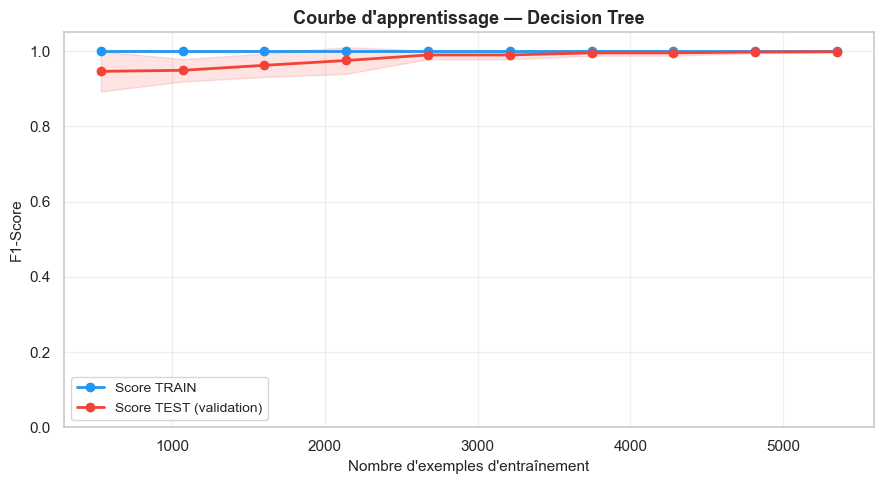

Score TRAIN final : 1.0000
Score TEST  final : 0.9984
Écart             : 0.0016
→ ✅ BON ÉQUILIBRE

=== SVM (rbf) ===


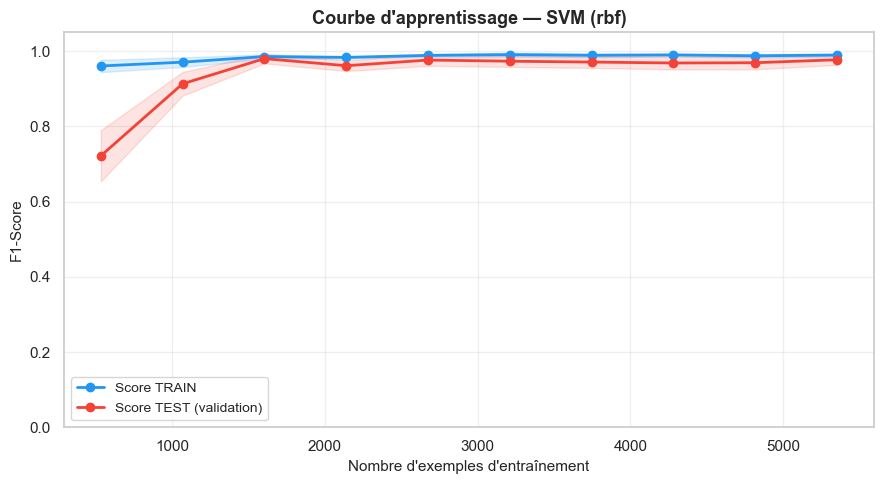

Score TRAIN final : 0.9896
Score TEST  final : 0.9771
Écart             : 0.0125
→ ✅ BON ÉQUILIBRE

=== KNN ===


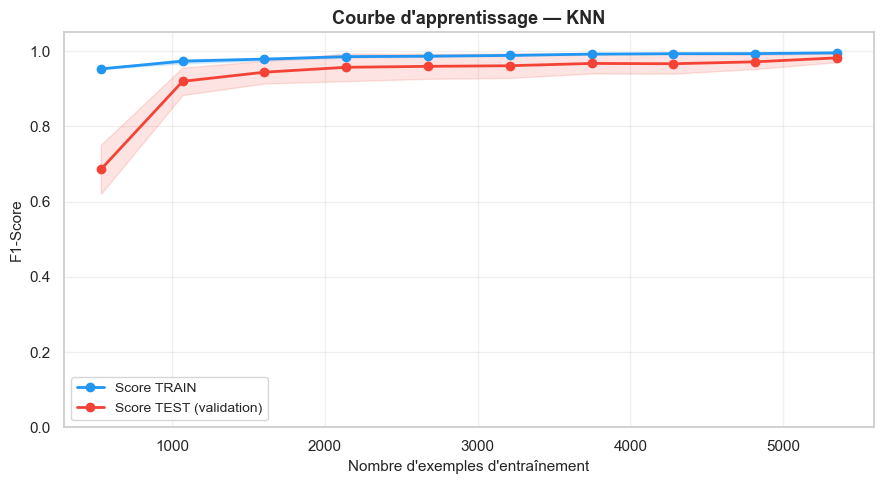

Score TRAIN final : 0.9955
Score TEST  final : 0.9822
Écart             : 0.0134
→ ✅ BON ÉQUILIBRE


In [14]:
modeles_test = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'SVM (rbf)'    : SVC(kernel='rbf', random_state=42),
    'KNN'          : KNeighborsClassifier(n_neighbors=3),
   
}

for nom, clf in modeles_test.items():
    print(f'\n=== {nom} ===')
    plot_learning_curve(clf, X, y, nom)

---
Matrices de Confusion

```
         VALEUR PREDITE
         Normal    Anomalie
REEL  Normal  [ TN  |  FP ]  ← fausses alarmes (moins grave)
      Anomalie[ FN  |  TP ]  ← DANGEREUX : panne non détectée
```
**FN = Faux Négatif = anomalie prédite comme normale → priorité absolue à minimiser**

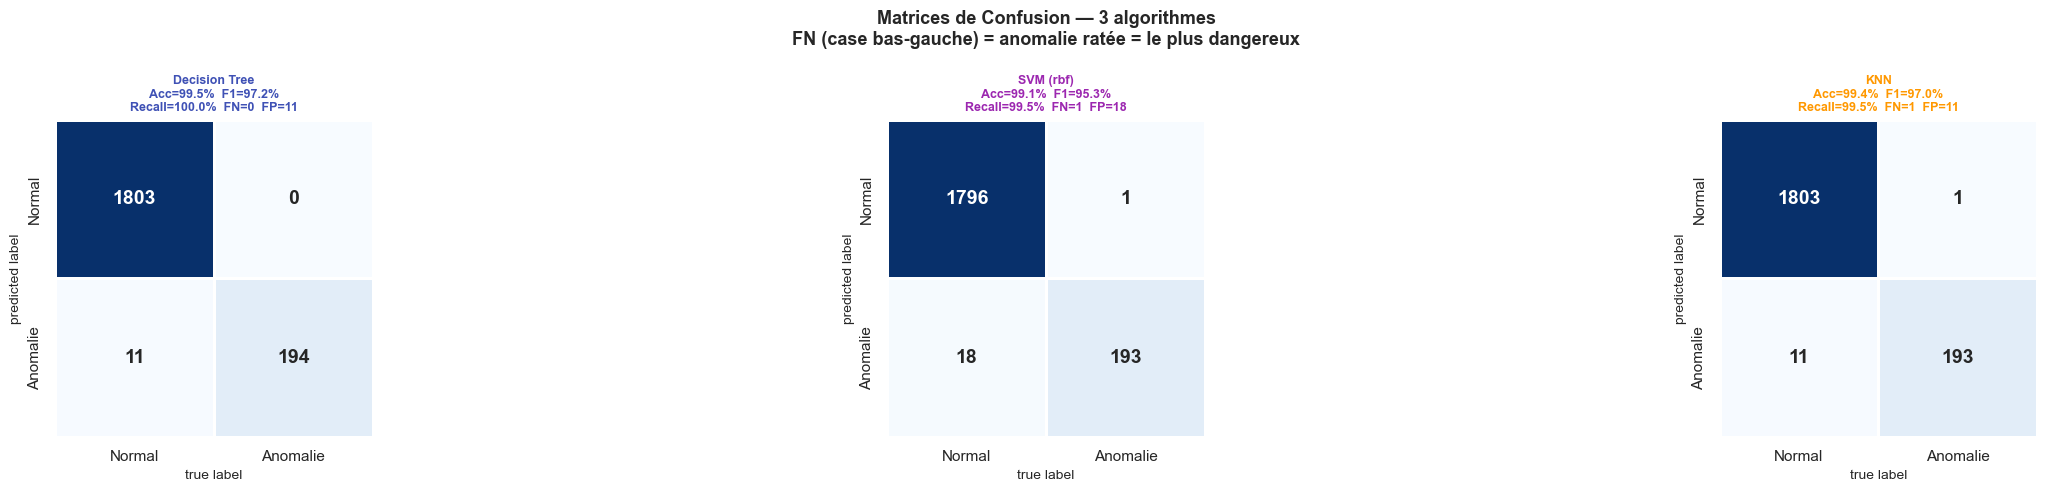

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(27, 5))
fig.suptitle('Matrices de Confusion — 3 algorithmes\n'
             'FN (case bas-gauche) = anomalie ratée = le plus dangereux',
             fontsize=13, fontweight='bold')

for ax, (nom, (y_pred, _)), col in zip(axes, PREDICTIONS.items(), ALGO_COLORS):
    mat = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = mat.ravel()

    sns.heatmap(
        mat.T, square=True, annot=True, fmt='d', cbar=False,
        ax=ax, cmap='Blues', linewidths=1, linecolor='white',
        xticklabels=['Normal', 'Anomalie'],
        yticklabels=['Normal', 'Anomalie'],
        annot_kws={'size': 14, 'weight': 'bold'}
    )
    ax.set_xlabel('true label',      fontsize=10)
    ax.set_ylabel('predicted label', fontsize=10)

    acc = (tp+tn)/mat.sum()*100
    f1  = f1_score(y_test, y_pred)*100
    rec = recall_score(y_test, y_pred)*100
    ax.set_title(
        f'{nom}\nAcc={acc:.1f}%  F1={f1:.1f}%\n'
        f'Recall={rec:.1f}%  FN={fn}  FP={fp}',
        fontsize=9, fontweight='bold', color=col
    )

plt.tight_layout()
plt.show()

---
## Cellule 13 — Courbes ROC + AUC

```
AUC = 1.00 → modèle parfait
AUC = 0.50 → modèle aléatoire (inutile)

Axe X = FPR (fausses alarmes)             → minimiser
Axe Y = TPR = Recall (anomalies détectées) → maximiser
```
**Avantage de l'AUC :** ne dépend pas du seuil de décision → comparaison objective.

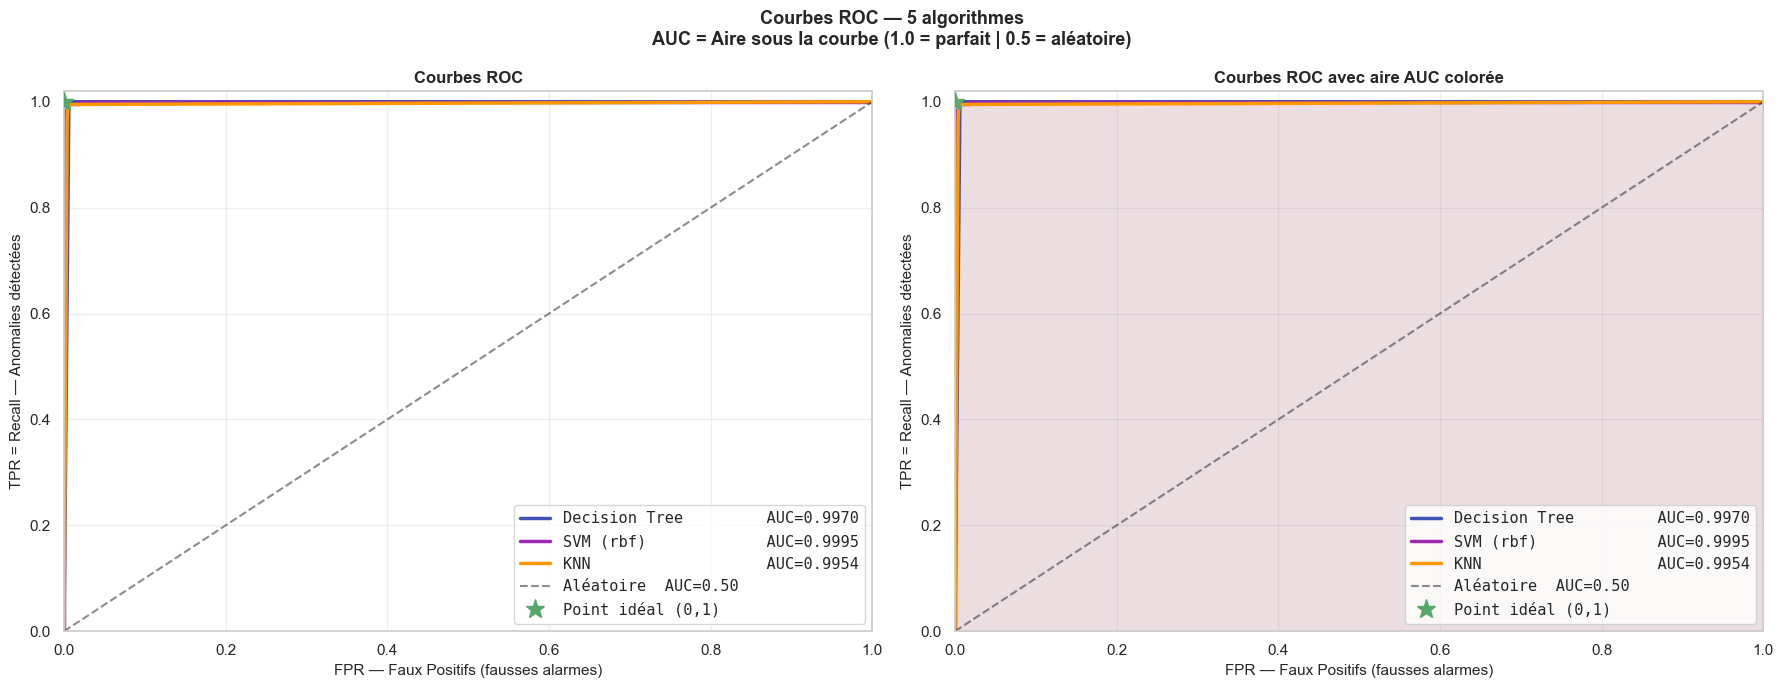

CLASSEMENT PAR AUC :
  SVM (rbf)             ███████████████████████████████████████  0.9995
  Decision Tree         ███████████████████████████████████████  0.9970
  KNN                   ███████████████████████████████████████  0.9954


In [16]:
# ─────────────────────────────────────────────────────────────────
# COURBES ROC — 5 algorithmes superposés
# ─────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('Courbes ROC — 5 algorithmes\n'
             'AUC = Aire sous la courbe (1.0 = parfait | 0.5 = aléatoire)',
             fontsize=13, fontweight='bold')

auc_scores = {}
for (nom, (_, y_proba)), col in zip(PREDICTIONS.items(), ALGO_COLORS):
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    auc_scores[nom] = auc
    for ax_i, ax in enumerate(axes):
        ax.plot(fpr, tpr, color=col, lw=2.5,
                label=f'{nom:<20s}  AUC={auc:.4f}')
        if ax_i == 1:
            ax.fill_between(fpr, tpr, alpha=0.07, color=col)

for ax in axes:
    ax.plot([0,1],[0,1],'k--', lw=1.5, alpha=0.5, label='Aléatoire  AUC=0.50')
    ax.plot(0, 1, 'g*', markersize=14, zorder=5, label='Point idéal (0,1)')
    ax.set_xlim([0,1]); ax.set_ylim([0,1.02])
    ax.set_xlabel('FPR — Faux Positifs (fausses alarmes)', fontsize=11)
    ax.set_ylabel('TPR = Recall — Anomalies détectées', fontsize=11)
    ax.legend(loc='lower right', fontsize=9, prop={'family':'monospace'})
    ax.grid(True, alpha=0.3)

axes[0].set_title('Courbes ROC', fontsize=12, fontweight='bold')
axes[1].set_title('Courbes ROC avec aire AUC colorée', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print('CLASSEMENT PAR AUC :')
for nom, auc in sorted(auc_scores.items(), key=lambda x: x[1], reverse=True):
    bar = chr(9608) * int(auc * 40)
    print(f'  {nom:20s}  {bar}  {auc:.4f}')

---
Tableau comparatif : toutes les métriques
---

,Accuracy %,Precision %,Recall %,F1-Score %,AUC-ROC,TN,FP (alarmes),FN (danger),TP
Decision Tree,99.45%,94.63%,100.00%,97.24%,0.9970,1803.000000,11.000000,0.000000,194.000000
SVM (rbf),99.05%,91.47%,99.48%,95.31%,0.9995,1796.000000,18.000000,1.000000,193.000000
KNN,99.40%,94.61%,99.48%,96.98%,0.9954,1803.000000,11.000000,1.000000,193.000000


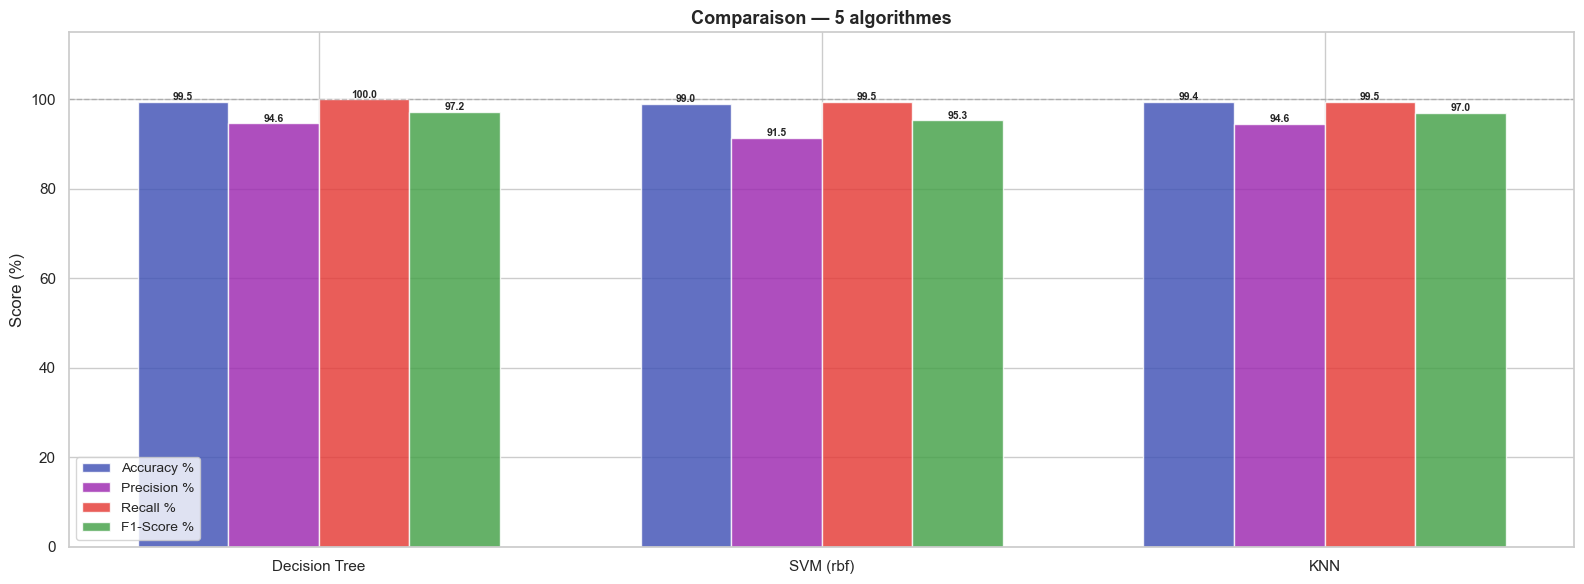

In [17]:
resultats = {}
for nom, (y_pred, y_proba) in PREDICTIONS.items():
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    resultats[nom] = {
        'Accuracy %'   : round(accuracy_score(y_test, y_pred)*100, 2),
        'Precision %'  : round(precision_score(y_test, y_pred, zero_division=0)*100, 2),
        'Recall %'     : round(recall_score(y_test, y_pred)*100, 2),
        'F1-Score %'   : round(f1_score(y_test, y_pred)*100, 2),
        'AUC-ROC'      : round(roc_auc_score(y_test, y_proba), 4),
        'TN'           : tn,
        'FP (alarmes)' : fp,
        'FN (danger)'  : fn,
        'TP'           : tp,
    }

df_res = pd.DataFrame(resultats).T

display(
    df_res.style
    .highlight_max(
        subset=['Accuracy %','Precision %','Recall %','F1-Score %','AUC-ROC','TN','TP'],
        color='#C8E6C9'
    )
    .highlight_min(
        subset=['FP (alarmes)', 'FN (danger)'],
        color='#C8E6C9'
    )
    .format({'Accuracy %':'{:.2f}%','Precision %':'{:.2f}%',
             'Recall %':'{:.2f}%','F1-Score %':'{:.2f}%','AUC-ROC':'{:.4f}'})
)

# Graphique barres
metrics_plot = ['Accuracy %','Precision %','Recall %','F1-Score %']
x, w = np.arange(len(PREDICTIONS)), 0.18
noms = list(PREDICTIONS.keys())

fig, ax = plt.subplots(figsize=(16, 6))
bar_cols = ['#3F51B5','#9C27B0','#E53935','#43A047']
for i, (met, col) in enumerate(zip(metrics_plot, bar_cols)):
    vals = [resultats[n][met] for n in noms]
    bars = ax.bar(x + i*w, vals, w, label=met, color=col, alpha=0.82)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.4,
                f'{v:.1f}', ha='center', fontsize=7.5, fontweight='bold')

ax.set_xticks(x + w*1.5)
ax.set_xticklabels(noms, fontsize=11)
ax.set_ylim(0, 115)
ax.set_ylabel('Score (%)')
ax.set_title('Comparaison — 5 algorithmes', fontsize=13, fontweight='bold')
ax.legend(fontsize=10)
ax.axhline(100, color='gray', ls='--', lw=1, alpha=0.4)
plt.tight_layout()
plt.show()

---
Cross-Validation 10-fold

**Pourquoi ?** Un seul test peut être chanceux. La CV teste sur 10 partitions → estimation fiable.  
**ImbPipeline** → SMOTE appliqué à l'intérieur de chaque fold, jamais sur le fold de test → **zéro data leakage**.

  Algorithme              F1 moyen      ±std       min       max
  ────────────────────────────────────────────────────────────
  Decision Tree             0.9908  ± 0.0073    0.9774    1.0000
  SVM (rbf)                 0.9584  ± 0.0150    0.9254    0.9771
  KNN                       0.9728  ± 0.0100    0.9559    0.9922


C:\Users\mahmo\AppData\Local\Temp\ipykernel_16160\4254565392.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = ax.boxplot(


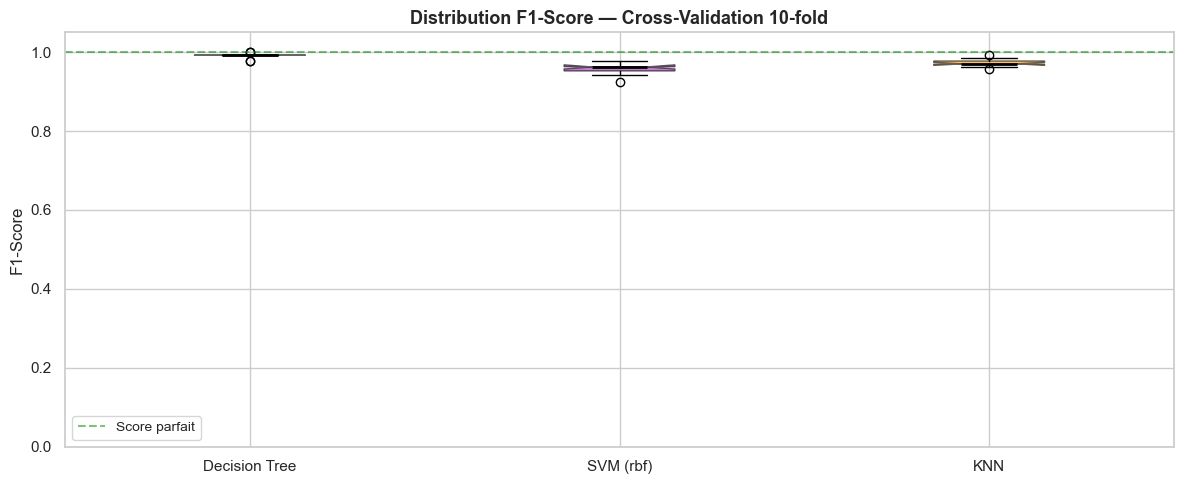

In [18]:
print(f'  {"Algorithme":20s}  {"F1 moyen":>10}  {"±std":>8}  {"min":>8}  {"max":>8}')
print('  ' + '─'*60)

for nom, scores in cv_all.items():
    print(f'  {nom:20s}  {scores.mean():>10.4f}  ±{scores.std():>7.4f}  '
          f'{scores.min():>8.4f}  {scores.max():>8.4f}')

# Boxplot
fig, ax = plt.subplots(figsize=(12, 5))
bplot = ax.boxplot(
    [cv_all[n] for n in cv_all.keys()],
    labels=list(cv_all.keys()),
    patch_artist=True, notch=True,
    medianprops=dict(color='black', lw=2)
)
for patch, col in zip(bplot['boxes'], ALGO_COLORS):
    patch.set_facecolor(col); patch.set_alpha(0.6)

ax.set_title('Distribution F1-Score — Cross-Validation 10-fold',
             fontsize=13, fontweight='bold')
ax.set_ylabel('F1-Score')
ax.set_ylim(0, 1.05)
ax.axhline(1.0, color='green', ls='--', lw=1.5, alpha=0.5, label='Score parfait')
ax.legend(fontsize=10)
plt.tight_layout()
plt.show()

---
Rapport Final
---

In [19]:
best_f1  = df_res['F1-Score %'].idxmax()
best_auc = df_res['AUC-ROC'].idxmax()
best_rec = df_res['Recall %'].idxmax()
best_cv  = max(cv_all, key=lambda n: cv_all[n].mean())

print('=' * 65)
print('  RAPPORT FINAL — DÉTECTION D\'ANOMALIES RÉSEAU FIBRE')
print('=' * 65)
print(f'''
DATASET
  Fichier       : dataset_ml.xlsx
  Lignes totales: {len(df)}
  Features ML   : {FEATURES}
  Normaux       : {(y==0).sum()} ({(y==0).mean()*100:.1f}%)
  Anomalies     : {(y==1).sum()} ({(y==1).mean()*100:.1f}%)

PRÉTRAITEMENT
  Split    : 70% train / 30% test (stratifié)
  SMOTE    : appliqué sur train uniquement
  Scaling  : StandardScaler (fit sur train SMOTE)

RÉSULTATS — TEST SET
  {'Algorithme':20s}  {'Accuracy':>9}  {'Recall':>8}  {'F1':>8}  {'AUC':>7}''')

for nom in PREDICTIONS:
    r = resultats[nom]
    star = ' ← MEILLEUR RECALL' if nom == best_rec else ''
    print(f"  {nom:20s}  {r['Accuracy %']:>8.1f}%  "
          f"{r['Recall %']:>7.1f}%  {r['F1-Score %']:>7.1f}%  "
          f"{r['AUC-ROC']:>7.4f}{star}")

print(f'''
CLASSEMENT
  Par F1-Score       : {best_f1}
  Par AUC-ROC        : {best_auc}
  Par Recall         : {best_rec}
  Par Cross-Val F1   : {best_cv}

RECOMMANDATION POUR RÉSEAU FIBRE
  FN = anomalie non détectée = panne = impact direct client
  → Priorité : maximiser Recall (minimiser FN)
  → Meilleur choix : {best_rec}  (Recall={resultats[best_rec]["Recall %"]:.1f}%)
''')
print('=' * 65)

  RAPPORT FINAL — DÉTECTION D'ANOMALIES RÉSEAU FIBRE

DATASET
  Fichier       : dataset_ml.xlsx
  Lignes totales: 6692
  Features ML   : ['F_SUSP', 'ADMIN_STATUS', 'OPER_STATUS', 'OLT_POWER_TX', 'OLT_RX_ONT_POWER', 'ONU_POWER_TX', 'ONU_POWER_RX']
  Normaux       : 6046 (90.3%)
  Anomalies     : 646 (9.7%)

PRÉTRAITEMENT
  Split    : 70% train / 30% test (stratifié)
  SMOTE    : appliqué sur train uniquement
  Scaling  : StandardScaler (fit sur train SMOTE)

RÉSULTATS — TEST SET
  Algorithme             Accuracy    Recall        F1      AUC
  Decision Tree             99.5%    100.0%     97.2%   0.9970 ← MEILLEUR RECALL
  SVM (rbf)                 99.0%     99.5%     95.3%   0.9995
  KNN                       99.4%     99.5%     97.0%   0.9954

CLASSEMENT
  Par F1-Score       : Decision Tree
  Par AUC-ROC        : SVM (rbf)
  Par Recall         : Decision Tree
  Par Cross-Val F1   : Decision Tree

RECOMMANDATION POUR RÉSEAU FIBRE
  FN = anomalie non détectée = panne = impact direct clie

---
## Conclusion
Les résultats montrent que les modèles SVM et Random Forest
sont les plus performants pour la détection d’anomalies.
Le rappel élevé garantit que la majorité des anomalies sont détectées.
---